# 10 - The Dynamic Workflow Engine: a Glass Box

**Part B - Petrophys Curriculum**

The dynamic workflow is the headline capability of `petrophys`: hand it a raw
well and it *inspects what curves are present*, decides which petrophysical
modules can run, chooses a method for each one, and executes the whole
interpretation pipeline in the correct order:

> QC -> Volume of clay -> Porosity -> Lithology -> Rw -> Water saturation ->
> Permeability -> Rock quality -> Net pay

The important word is **dynamic**. Nothing is hard-coded to a fixed curve list.
If a well has no resistivity, the saturation step is skipped with a recorded
reason rather than crashing. Rw needs a supported input or calculation route;
the workflow does not silently introduce a default Rw. If only a density log is
present, porosity falls back to a density-only route.

This lesson treats the engine as a **glass box**. We do not just read the
final answer - we read the *step trace*: which steps executed, which were
skipped and why, the method chosen per step, and the exact parameters used.
Then we prove it is steerable by overriding the saturation model and the Sw
cutoff and measuring the change in net pay over the Brent reservoir interval.

## Learning goals

- Run `pp.interpret` on a real well and read the `DynamicWorkflowResult` it returns.
- Understand how the engine **auto-detects** available input curves, selects
  a method per module, and records why a step was skipped.
- Inspect the **step trace**: executed vs skipped steps, method, inputs,
  outputs, parameters, and human-readable decisions.
- Plot resulting curves (VCL, PHIE, SW) against the raw logs.
- Demonstrate **parameter overrides** - change the Sw model and the Sw cutoff
  one knob at a time and decompose their effects on net pay inside a chosen
  reservoir window with `result.summary(top=..., bottom=...)`.
- Understand copy-by-default behavior and explicit lithology source selection.
- Summarise pay per formation with `result.formation_summary(rank="formation")`
  and recognise cutoff flags that need geological review.

### Prerequisites

Familiarity with the individual modules (clay volume, porosity, saturation,
net pay) from Part A helps, but this lesson is self-contained.

## Why this matters

A manual petrophysical interpretation is a long chain of decisions: *which*
clay indicator, *which* porosity route given the logs you have, *which*
saturation equation for this shaliness, *what* cutoffs for net pay. Each choice
depends on the previous one and on the curves actually available in the file.

The dynamic workflow encodes that decision chain once and makes it auditable.
The step trace is what turns an opaque "the model says there are N metres of pay" into a
defensible interpretation you can hand to a reviewer.

In [1]:
%matplotlib inline
from petrophys.visualization import use_plot_style
use_plot_style()
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys as pp
from petrophys.workflow import DynamicWorkflowConfig, run_dynamic_workflow_with_zones

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
print("petrophys", pp.__version__)

petrophys 3.0.0


## 1. Read and plot before interpretation

We use 30/6-5, a North Sea clastic well with embedded vendor lithology. No
external formation or lithology file is required. `pp.read` only loads data;
`pp.plot` displays existing curves.

The file carries a genuine unit problem: the core saturation curves `SWC` and
`SOC` are stored in percent although the LAS header labels them `frac`, so
Petrophys divides them by 100 whenever it standardizes the curves. The plot
does not raise a warning for it; it records the note in `raw_viewer.warnings`,
which the cell prints. `pp.interpret` raises the same note as a `UserWarning`
for each curve on every run, so after reading it once we silence **only that
message** before the runs below.

`pp.interpret` works on a copy, so we can keep the raw well unchanged and reuse
it for several configurations.

Well: 30/6-5
Depth: 176.60999 3556.08032 m
Curves: LITHOLOGY_GEOLINK, CALI, DRHO, NPHI, RHOB, PEF, GR, DTC, DTE, RDEP, SP, RSHA, RMED, BS, PHIC, GDEN, KH_CORE, KV_CORE, SWC, SOC


[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:750: UserWarning: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:750: UserWarning: SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)


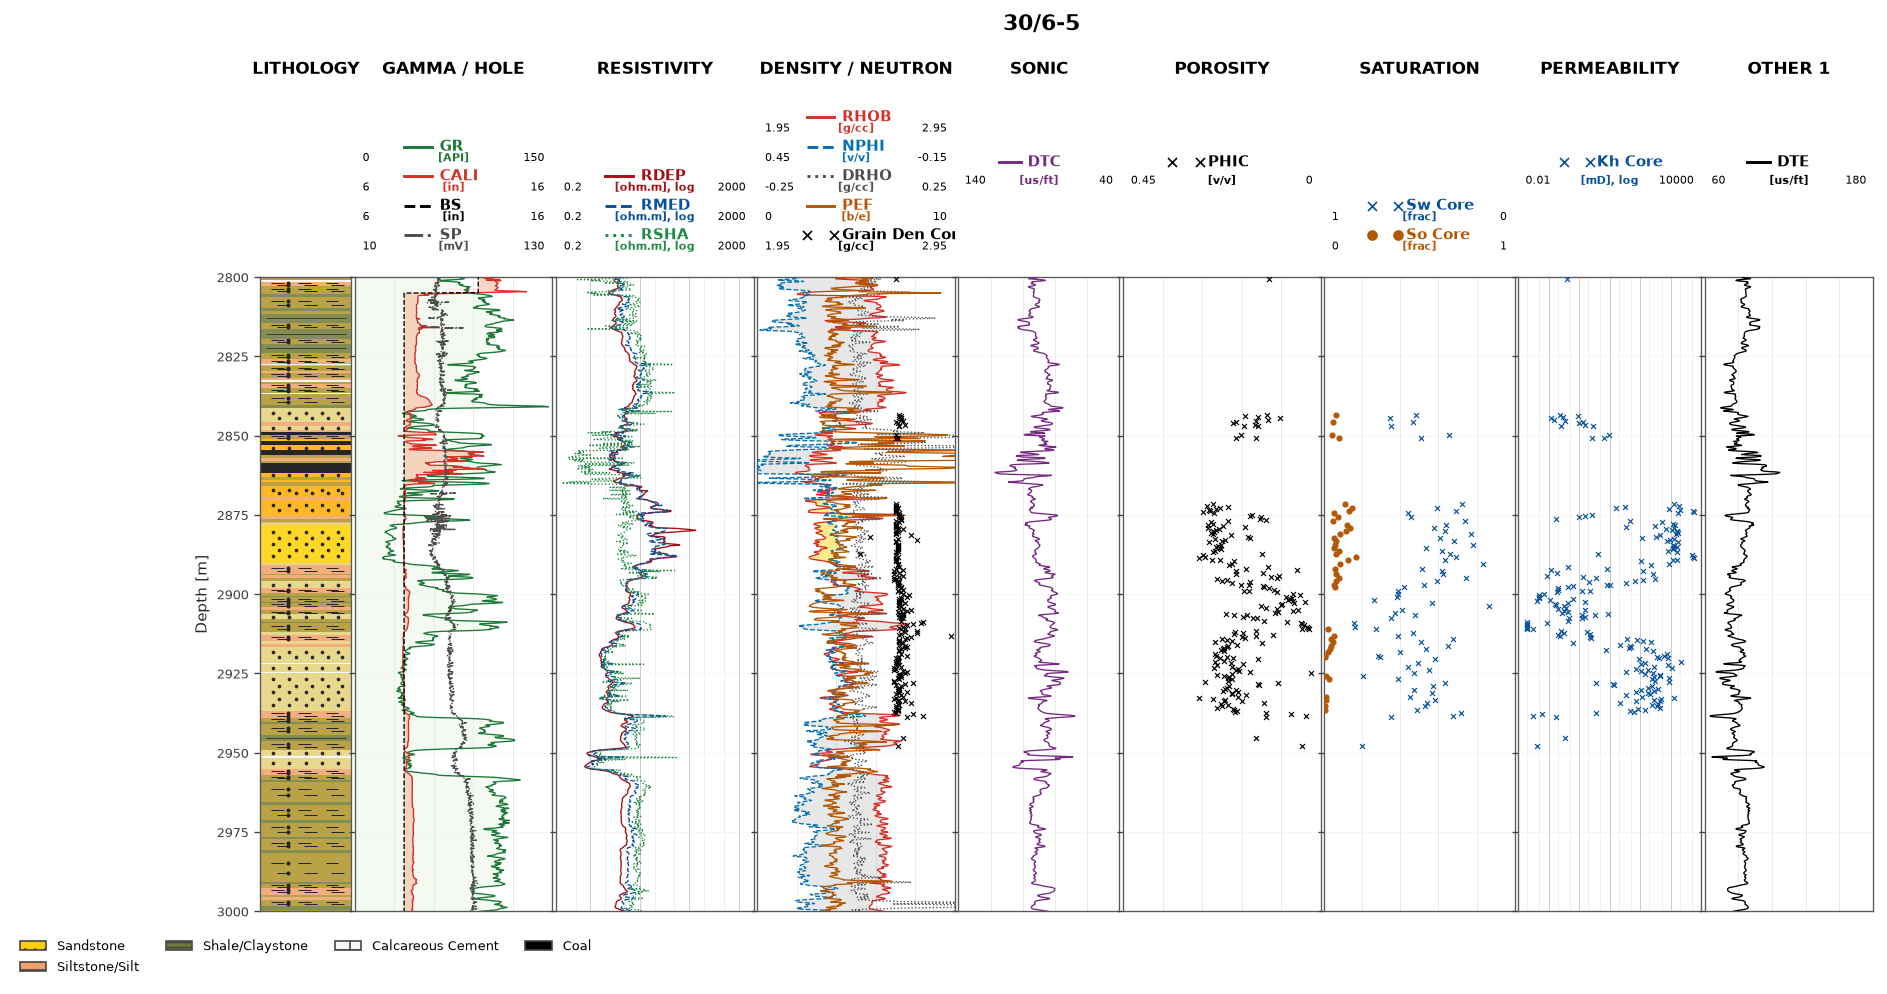

Viewer notes: ["SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.", "SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units."]


In [2]:
def load_well():
    """Return a fresh, unprocessed LAS well."""
    return pp.read(pp.sample("30_6-5"))

raw = load_well()
print("Well:", raw.name)
print("Depth:", raw.top, raw.bottom, raw.depth_unit)
print("Curves:", ", ".join(raw.curves))
raw_viewer = pp.plot(raw, depth_range=(2800, 3000), figsize=(14, 8))
raw_viewer.show()
print("Viewer notes:", raw_viewer.warnings)
raw_viewer.close()

# The SWC/SOC percent-vs-'frac' note has been read above; hide only that
# message so it does not repeat for every run below. Other warnings still show.
warnings.filterwarnings(
    "ignore", message=r"(SWC|SOC): inferred percent core saturation", category=UserWarning
)

### What can the engine detect?

Before each step runs, the workflow checks that the step's inputs are present
(for example, saturation needs a deep resistivity, a porosity and an Rw
source). A step whose prerequisites are missing is skipped, and the reason is
recorded in `result.specific_steps_skipped` - you will read those reasons in
section 3. Here we simply probe the raw file for the curve families those
checks look for, so you can see, *before* running anything, which inputs are
present.

In [3]:
# Curve families the workflow's prerequisite checks look for (a representative list)
probe = ["GR", "SP", "NPHI", "RHOB", "DTC", "DTS", "RDEP", "RT",
         "RSHA", "RXO", "PEF", "CALI", "BS", "DRHO",
         "PHIC", "KH_CORE", "SWC", "SOC"]
present = [name for name in probe if raw.has_curve(name)]
missing = [name for name in probe if not raw.has_curve(name)]
print("Detected inputs :", ", ".join(present))
print("Not present     :", ", ".join(missing))

Detected inputs : GR, SP, NPHI, RHOB, DTC, RDEP, RSHA, PEF, CALI, BS, DRHO, PHIC, KH_CORE, SWC, SOC
Not present     : DTS, RT, RXO


#### What the detected inputs enable

- **GR** enables clay-volume estimation.
- **RHOB, NPHI, and PEF** support porosity and multi-mineral lithology.
- **RDEP** supports formation-water, saturation, and invasion calculations.
- **PHIC and KH_CORE** enable log-to-core calibration.

The workflow evaluates these prerequisites explicitly before selecting each
step.


## 2. Configure the run

`DynamicWorkflowConfig` holds the interpretation settings, and every field is
optional. Anything left `None` is read from the LAS header, derived from the
data, or set to a documented default - including the net-pay cutoffs, which
resolve per sample to the standard cutoffs of the sample's lithology family
(`STANDARD_CUTOFFS`). The trace records
the values actually used (section 4 prints them). Settings are validated when
the config is created, so a misspelt choice fails immediately with a
suggestion instead of being ignored.

The 30/6-5 LAS header carries the operator's parameter block (BHT, Rw with its
measurement temperature `RWT`, Rmf, mud-filtrate chlorides), so the environment
comes from the file rather than from guesses. Rw still deserves a check rather
than trust: the header gives **0.070 ohm.m at 230 degF**, the value lesson 09
back-calculates from the operator's evaluation and case study 1 cross-checks
against the NPD fact page. We pass it explicitly with its temperature
(`rw=0.070, rw_meas_temp_f=230`), so the run does not depend on header parsing,
and the decision is recorded here and in the trace. Without `rw_meas_temp_f`
the workflow would take Rw at the median formation temperature, which changes
the computed saturation strongly.

The `salinity_ppm` setting comes from the filtrate chloride `CLFL`, converted to
NaCl equivalent by hand as in lesson 06 (x 1.645, with mg/l taken as ppm for this
dilute filtrate). `pp.interpret` reads a header `CLFL` itself, as chlorides in
mg/l converted with the brine density, when it needs the filtrate salinity for
Rmf (setting `rmf_chlorides_mg_l`); here Rmf comes from the header `RMF`, passed
as `rmf_at_meas_temp`.

In [4]:
hdr = load_well()   # peek at the LAS ~Params block
BHT_F = float(hdr.get_parameter("BHT")) * 9.0 / 5.0 + 32.0   # header BHT is in degC
SALINITY_PPM = float(hdr.get_parameter("CLFL")) * 1.645      # chloride -> NaCl equivalent

ENV = DynamicWorkflowConfig(
    # --- environment from the LAS header (Rw checked in lesson 09) ---
    bht_f=round(BHT_F, 1),         # header BHT converted to degF
    td_ft=11700.0,                 # ~3566 m total depth in feet
    rw=0.070,                      # header RW, checked in lesson 09
    rw_meas_temp_f=230.0,          # temperature at which that Rw applies, degF
    salinity_ppm=round(SALINITY_PPM),
    rmf_at_meas_temp=float(hdr.get_parameter("RMF")),
    # --- interpretation choices ---
    lithology_domain="clastic",
    matrix_type="sandstone",
    sw_model="auto",        # let the router pick per depth
    # net-pay cutoffs left unset -> the workflow's clastic defaults (see section 4)
)
print("Environment (header-derived; cite the Rw source in any report):")
for k in ["bht_f", "td_ft", "rw", "rw_meas_temp_f", "salinity_ppm", "rmf_at_meas_temp"]:
    print("  %-16s = %s" % (k, getattr(ENV, k)))

# Settings are validated on creation: a typo raises instead of being ignored.
try:
    DynamicWorkflowConfig(sw_model="simandoox")
except ValueError as exc:
    print("\nValueError:", exc)

Environment (header-derived; cite the Rw source in any report):
  bht_f            = 258.8
  td_ft            = 11700.0
  rw               = 0.07
  rw_meas_temp_f   = 230.0
  salinity_ppm     = 33502
  rmf_at_meas_temp = 0.08

ValueError: Invalid DynamicWorkflowConfig:
  - sw_model='simandoox' is not valid; use one of: auto, archie, north_sea, nigeria_schlumberger, simandoux, indonesia, dual_water, waxman_smits (did you mean 'simandoux'?)


## 3. Run the pipeline with explicit assumptions

`pp.interpret(raw, config=ENV)` returns a `DynamicWorkflowResult` and leaves
`raw` unchanged; the calculated curves live on `result.well`. You can also pass
individual settings as keywords, e.g. `pp.interpret(raw, rw=0.07,
rw_meas_temp_f=230)`, as section 6 does.

The lower-level `pp.run_dynamic_workflow(well, config)` does the same work but
adds the curves to the well you pass in. Prefer `pp.interpret`; section 7 shows
the one place this lesson needs an in-place helper.

The Rw in `ENV` is a documented choice for this well; do not transplant it to an
unrelated well.

In [5]:
import textwrap

before = tuple(raw.curves)
result = pp.interpret(raw, config=ENV)
result.raise_for_errors()
well = result.well
assert well is not raw
assert tuple(raw.curves) == before
print("Status  :", result.status)
print(textwrap.fill("Executed: " + ", ".join(step.step for step in result.steps_executed),
                    width=100, subsequent_indent="          "))
print("Skipped :", ", ".join(result.steps_skipped))
print("Warnings:", result.warnings or "none")

Status  : interpreted
Executed: normalization, input_context, temperature, bad_hole, vclay, rcl, rmf, porosity, lithology,
          core_correction, rw, invasion, saturation, permeability, rock_quality, bvw, mhi, net_pay
Skipped : spectral_gamma, elemental_spectroscopy, hc_correction, porosity_refinement
Warnings: none


### Why were those steps skipped?

`result.steps_skipped` lists the steps that did not run, and
`result.specific_steps_skipped` maps each one to a plain-language reason: a
missing input, an opt-in step you did not request (such as the hydrocarbon
correction), or a calculation that is available as a separate function rather
than inside this workflow. A skipped step is not an error.

`result.status` is `"interpreted"` when at least one interpretation step
produced curves, `"no_interpretation"` when nothing usable was computed, and
`"failed"` when a step failed. `result.raise_for_errors()` stops on failures;
pass `raise_on_error=True` to re-raise the original exception during the run.

In [6]:
if result.specific_steps_skipped:
    for step, reason in result.specific_steps_skipped.items():
        print("%-22s -> %s" % (step, reason))
else:
    print("No step recorded a skip reason.")
print()

# Rw and Rmf are temperature-corrected along the well, so print their range.
def value_range(v):
    a = np.asarray(v, dtype=float)
    a = a[np.isfinite(a)]
    if a.size == 0:
        return "n/a"
    if a.size == 1:
        return "%.4f" % a[0]
    return "%.4f - %.4f" % (a.min(), a.max())

print("Rw computed  :", value_range(result.rw_computed), "ohm.m")
print("Rmf computed :", value_range(result.rmf_computed), "ohm.m")

spectral_gamma         -> Not run by the interpretation workflow; use petrophys.interpretation.geochemistry.interpret_spectral_gamma directly
elemental_spectroscopy -> Not run by the interpretation workflow; use petrophys.interpretation.geochemistry.interpret_elemental_spectroscopy directly
hc_correction          -> apply_hc_correction=False (hydrocarbon correction is opt-in)
porosity_refinement    -> Not run by the interpretation workflow; porosity is computed once in the porosity step

Rw computed  : 0.0625 - 0.1968 ohm.m
Rmf computed : 0.0247 - 0.0777 ohm.m


### Which lithology source did this run select?

The `input_context` trace records source selection and availability. Auto prefers attached external intervals, then a recognized vendor log, otherwise computed lithology. Alternatives are `external`, `vendor`, `computed`, or explicit `config` matrix/lithology.

To use an external file in both plotting and interpretation, attach it with `pp.read(..., lithology=...)` or pass `lithology_intervals` to the workflow. Missing requested inputs fail. No external file is needed for the solver route; lesson 05 demonstrates it with measured logs only.

Vendor codebooks are not universal. This example uses the recognized GeoLink curve, not arbitrary integer labels.

In [7]:
context_step = next(step for step in result.steps_executed if step.step == "input_context")
print(context_step.parameters)
print("Raw source still has", len(raw.curves), "curves")

{'requested_source': 'auto', 'selected_source': 'vendor', 'external_available': False, 'vendor_available': True, 'vendor_curve': 'LITHOLOGY_GEOLINK'}
Raw source still has 20 curves


## 4. The glass box: the step trace table

This is the heart of the lesson. `result.to_dataframe()` renders one row per
executed step with the **method chosen**, the **input curves consumed**, the
**output curves written**, and the **decisions** taken. Read it top to bottom -
it is the audit trail of the interpretation.

In [8]:
trace = result.to_dataframe()

def short_list(text, keep=4):
    """Shorten a comma-separated curve list for display; the trace keeps all names."""
    names = [n for n in text.split(", ") if n]
    return ", ".join(names[:keep]) + (" ... (+%d)" % (len(names) - keep) if len(names) > keep else "")

# Compact view: what ran and how.
compact = trace[["Step", "Status", "Method", "Input Curves", "Output Curves"]].copy()
for col in ["Input Curves", "Output Curves"]:
    compact[col] = compact[col].map(short_list)
print(compact.to_string(index=False))

           Step Status                                      Method                      Input Curves                                Output Curves
  normalization     OK        curve_alias_and_unit_standardization     BS, CALI, DRHO, DTC ... (+16)                  DRHO, PEF, GR, DTC ... (+2)
  input_context     OK                 validated_geology_selection                                                                               
    temperature     OK                    linear_gradient_from_BHT                                                                           TEMP
       bad_hole     OK                          caliper_drho_flags     CALI, BS, DRHO, RHOB ... (+1)                                     BAD_HOLE
          vclay     OK                                      linear                GR, SP, NPHI, RHOB           VCL, VCLAY, VCL_GR, VCLGR ... (+4)
            rcl     OK                   lithology_shale_median_rt                         RDEP, VCL                        

### Zooming in on a single step's reasoning

Each `StepResult` also carries free-text `decisions` - the branch logic the
module took. Let's inspect the **saturation** step, which is where the method
routing is most interesting.

In [9]:
sat = next(s for s in result.steps_executed if s.step == "saturation")
print("Step       :", sat.step)
print("Method     :", sat.method)
print("Inputs     :", ", ".join(sat.input_curves))
print("Outputs    :", ", ".join(sat.output_curves))
print("Key parameters (sat.parameters holds the full set):")
for k in ["sw_model_requested", "sw_model_sample_counts", "vcl_cutoff_for_routing",
          "salinity_ppm", "m", "n", "rw_min", "rw_max"]:
    v = sat.parameters.get(k)
    print("   %-24s %s" % (k, ("%.4g" % v) if isinstance(v, float) else v))
print("Decisions  :")
for d in sat.decisions:
    print("   -> " + d)

Step       : saturation
Method     : archie+simandoux
Inputs     : RDEP, PHIE_CC, VCL
Outputs    : SW, SXO
Key parameters (sat.parameters holds the full set):
   sw_model_requested       auto
   sw_model_sample_counts   {'archie': 10472, 'simandoux': 11704}
   vcl_cutoff_for_routing   0.3
   salinity_ppm             33502
   m                        2
   n                        2
   rw_min                   0.06254
   rw_max                   0.1968
Decisions  :
   -> Model selected: archie+simandoux
   -> Auto-routing: depth-by-depth model selection based on VCLAY and lithology
   -> Depth routing counts: archie=10472, simandoux=11704
   -> Dual Water needs a supplied Rwb, which is not estimated: 1468 shaly carbonate samples used the Simandoux equation (set rwb to use Dual Water)
   -> Archie coefficients from lithology (ground_truth_lithology_geolink)
   -> Rw range = 0.0625 to 0.1968, Rcl = 2.9059999999999997
   -> SXO from invaded-zone Archie where RXO/RSHA/RESS and RMF were finit

The method string lists every equation the router used, and
`sw_model_sample_counts` says how many samples went to each. The router did not
pick one global equation - it chose **per depth sample** from shaliness and
lithology:

- VCL below `vcl_cutoff_for_routing` (clean rock) -> **Archie**;
- shaly samples that the lithology log marks as carbonate -> **Dual-Water**, but
  only with a supplied bound-water resistivity `rwb`, which the workflow never
  estimates. Without it, as here, they take the clastic routing below, and a
  decision line counts them;
- other shaly samples -> **Waxman-Smits** when you supply `cec` and `b_coeff`,
  otherwise **Simandoux** when the formation-water salinity is at least
  20,000 ppm and **Indonesia** (the published Poupon-Leveaux equation) below
  that. Our salinity comes from the header's mud-filtrate chloride converted to
  NaCl equivalent; lesson 06 shows the formation water is about as salty as the
  filtrate, so it stands in for the formation-water salinity here.

That per-depth routing is what a manual interpreter does by hand, and the
trace shows it sample by sample. Note also the porosity input: `PHIE_CC` is the
core-corrected porosity written by the `core_correction` step. 30/6-5 carries
core porosity; the step fits it to total porosity and writes `PHIE_CC` only when
the fit passes a quality gate (at least 8 core-log pairs, a positive slope and an
r$^2$ of at least 0.5).

### Which net-pay cutoffs did the run use?

We left the cutoffs unset, so the workflow resolved them: each sample takes the
standard cutoffs of its lithology family (`STANDARD_CUTOFFS`: clastic VCL < 0.40,
PHIE > 0.08, SW < 0.60; carbonate VCL < 0.30, PHIE > 0.045, SW < 0.70), with the
family read from the vendor lithology log. The `net_pay` step records the values
(`lithology_dependent` where the families differ), where they came from
(`cutoff_source`), and how many samples passed each successive cutoff. It also
leaves non-reservoir samples out of net reservoir and pay - bad hole
(`BAD_HOLE`), evaporite and coal, and halite recognised from its logs - and its
decision lines say how much thickness each removed (a category absent from
the well gets no line). Those counts cover the
**whole logged well**, including the shallow overburden - section 6 explains why
a whole-well total is not a reservoir number.

In [10]:
pay_step = next(s for s in result.steps_executed if s.step == "net_pay")
for k in ["vcl_cutoff", "phie_cutoff", "sw_cutoff", "cutoff_source"]:
    print("%-14s %s" % (k, pay_step.parameters.get(k)))
# The decisions up to the seal flag: the three cutoff stages, where unset
# cutoffs came from, and the samples left out of net reservoir and pay.
for d in pay_step.decisions:
    if d.startswith("SEALFLAG"):
        break
    print("   -> " + d)

vcl_cutoff     lithology_dependent
phie_cutoff    lithology_dependent
sw_cutoff      lithology_dependent
cutoff_source  {'vcl_cutoff': 'lithology_family_standard', 'phie_cutoff': 'lithology_family_standard', 'sw_cutoff': 'lithology_family_standard'}
   -> NET_ROCK: VCL < 0.4 clastic, 0.3 carbonate -> 12486 samples (1902.2 m)
   -> NET_RES:  + PHIE_CC > 0.08 clastic, 0.045 carbonate -> 5435 samples (828.0 m)
   -> NET_PAY:  + SW < 0.6 clastic, 0.7 carbonate -> 296 samples (45.1 m)
   -> vcl_cutoff, phie_cutoff, sw_cutoff not set: lithology-family standards (STANDARD_CUTOFFS) for 20393 clastic samples, 1783 carbonate samples
   -> Coal is not reservoir rock (low density and high resistivity pass the cutoffs): 47 samples left out of NET_RES and NET_PAY, removing 0.0 m of net reservoir and 0.0 m of net pay
   -> Bad hole (BAD_HOLE = 1): density, neutron, PHIE and SW are unreliable: 12631 samples left out of NET_RES and NET_PAY, removing 944.6 m of net reservoir and 104.8 m of net pay


## 5. Plot the resulting curves

A glass box should let you *see* the outputs, not just tabulate them.
`pp.plot` accepts the result directly. The `"petrophysics"` template overlays
the raw triple-combo inputs with computed curves - volume of clay (`VCL`),
effective porosity (`PHIE`), water saturation - plus the net-pay flag. We
restrict the window to the Brent-to-Statfjord reservoir section.

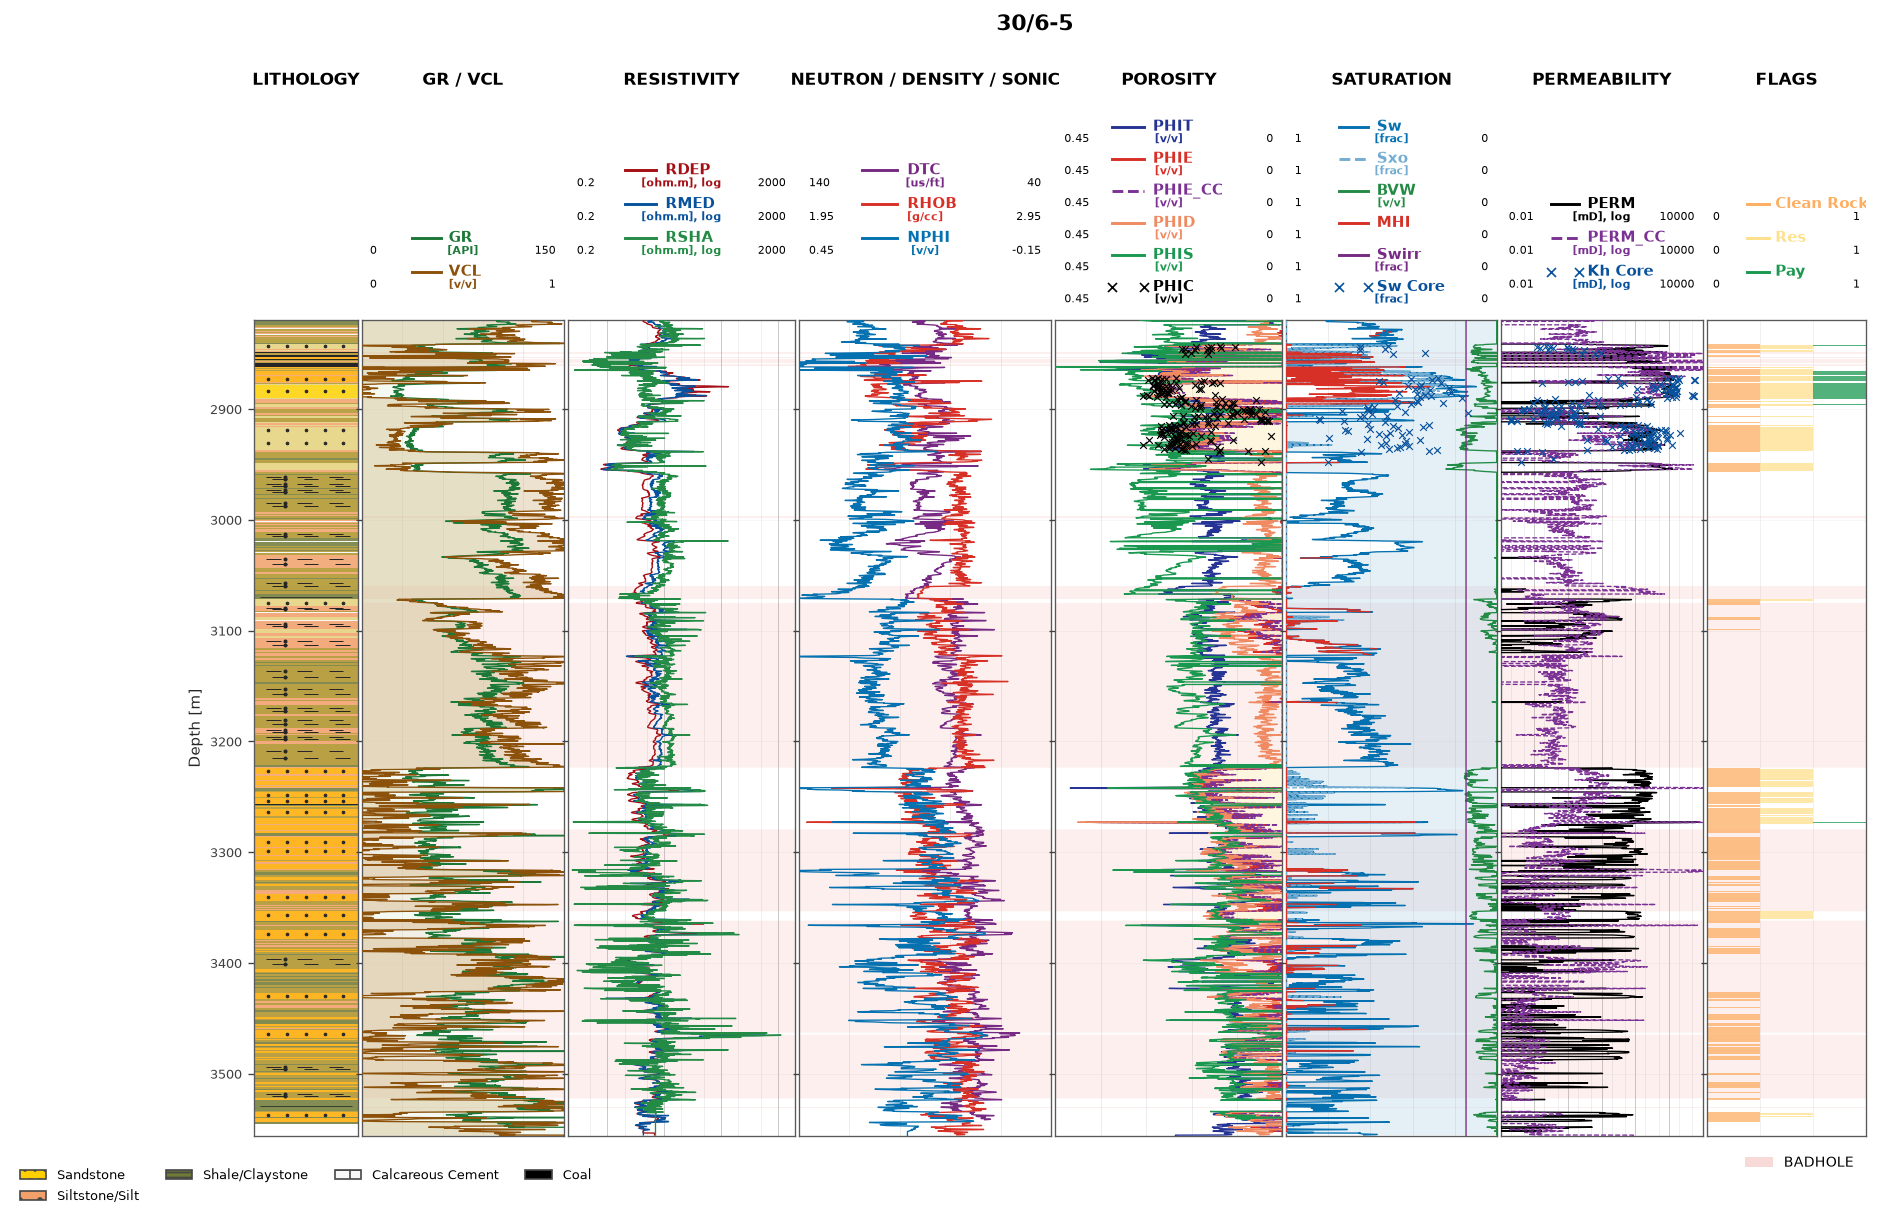

Omitted tracks: []


In [11]:
top, bot = 2820.0, min(3560.0, well.bottom)
viewer = pp.plot(result, template="petrophysics", depth_range=(top, bot), figsize=(14, 10))
viewer.show()
viewer.close()
print("Omitted tracks:", viewer.diagnostics["omitted_tracks"])

The clay volume climbs in the shales (high GR), effective porosity opens up in
the clean sands, and the net-pay flag lights up only where all three cutoffs
pass at once: clay below the VCL cutoff, porosity above the PHIE cutoff, and
water saturation below the Sw cutoff. The `bad_hole` step writes a `BAD_HOLE`
flag, and the net-pay step leaves those samples out of net reservoir and pay,
because density, neutron, PHIE and SW are unreliable there (section 4 printed the
thickness this removed). Where a well has no bit size (no BS curve or header
value), the caliper tests cannot run, so `BAD_HOLE` there comes from the density
correction alone, |DRHO| > 0.15 g/cm3.

## 6. Parameter overrides: change one choice at a time

A -> B changes the saturation model at a fixed cutoff; B -> C tightens the Sw
cutoff at a fixed model. All three runs start from the same raw well because
`pp.interpret` copies it, and all three pin the VCL and PHIE cutoffs
explicitly, so only the named knob changes.

We measure net pay over the **Brent Group reservoir, 2841-2958 m** (the Ness and
Etive formations; the bundled tops label the group `BAAT GP.`).
`result.summary(top=..., bottom=...)` returns the net-rock, net-reservoir and
net-pay thickness inside a depth window.

In [12]:
BRENT_TOP, BRENT_BASE = 2841.0, 2958.0   # Brent Group (Ness + Etive), metres

def net_pay(run, top=None, bottom=None):
    """Net-pay thickness in [top, bottom] (the whole well when both are None)."""
    return run.summary(top=top, bottom=bottom)["net_thickness"]["net_pay"]

# Same header-derived environment as section 2; the VCL and PHIE cutoffs are
# pinned so that only the Sw model or the Sw cutoff changes between runs.
BASE = dict(bht_f=ENV.bht_f, td_ft=ENV.td_ft, rw=0.070, rw_meas_temp_f=230.0,
            salinity_ppm=ENV.salinity_ppm, rmf_at_meas_temp=ENV.rmf_at_meas_temp,
            lithology_domain="clastic", matrix_type="sandstone",
            vcl_cutoff=0.4, phie_cutoff=0.08)

runs = {
    "A": pp.interpret(raw, sw_model="simandoux", sw_cutoff=0.6, **BASE),  # base assumptions
    "B": pp.interpret(raw, sw_model="archie", sw_cutoff=0.6, **BASE),     # model changed
    "C": pp.interpret(raw, sw_model="archie", sw_cutoff=0.5, **BASE),     # cutoff changed
}
for run in runs.values():
    run.raise_for_errors()
rA, rB, rC = runs["A"], runs["B"], runs["C"]

pA, pB, pC = (net_pay(run, BRENT_TOP, BRENT_BASE) for run in (rA, rB, rC))
print("Net pay in the Brent window (%.0f-%.0f m):" % (BRENT_TOP, BRENT_BASE))
print("  Run A: simandoux, Sw cutoff 0.60 -> %5.1f m" % pA)
print("  Run B: archie,    Sw cutoff 0.60 -> %5.1f m" % pB)
print("  Run C: archie,    Sw cutoff 0.50 -> %5.1f m" % pC)
print()
print("Decomposition of the total change A - C (%.1f m):" % (pA - pC))
print("  model effect  (A - B, same cutoff) : %5.1f m" % (pA - pB))
print("  cutoff effect (B - C, same model)  : %5.1f m" % (pB - pC))

Net pay in the Brent window (2841-2958 m):
  Run A: simandoux, Sw cutoff 0.60 ->  28.6 m
  Run B: archie,    Sw cutoff 0.60 ->  24.5 m
  Run C: archie,    Sw cutoff 0.50 ->  21.5 m

Decomposition of the total change A - C (7.2 m):
  model effect  (A - B, same cutoff) :   4.1 m
  cutoff effect (B - C, same model)  :   3.1 m


### Read the printed output

The printed decomposition separates the model effect (A - B) from the cutoff
effect (B - C). Results depend on the data, source selection and parameters,
so compare the numbers printed above rather than values quoted elsewhere.
Forcing `sw_model` replaces the automatic per-depth routing;
that is appropriate for a controlled sensitivity experiment, not proof that one
model is universally right.

### Why a reservoir window, not the whole well?

The cell below totals the same three runs over the Brent window, over the
shallow section above the Rogaland Group top (1908 m in the bundled tops), and
over the whole logged well (176-3556 m). Compare the columns. Flags above
1908 m sit in the Tertiary overburden (the Nordland and Hordaland groups;
section 7 shows where): poorly compacted sediments that read very high apparent porosity, where the clay
indicators disagree, and where one Rw - corrected for temperature, at constant
salinity - serves the whole well although shallow formation water is usually
fresher. Samples there can pass all three cutoffs without being a hydrocarbon
reservoir. Cutoffs describe rock and fluid properties; they do not know where the
reservoir is. Choose the interval from geology first, then apply the cutoffs - a
whole-well total mixes the reservoir with whatever the overburden flags. Reading
the result per formation, or giving the shallow section its own Rw through zoned
header parameters (section 7), addresses the same problem.

In [13]:
SHALLOW_BASE = 1908.0   # top of the Rogaland Group in the bundled tops, metres
table = pd.DataFrame([
    {"Run": name,
     "Brent window (m)": net_pay(run, BRENT_TOP, BRENT_BASE),
     "Above %.0f m (m)" % SHALLOW_BASE: net_pay(run, None, SHALLOW_BASE),
     "Whole well (m)": net_pay(run)}
    for name, run in runs.items()
])
print(table.round(1).to_string(index=False))

Run  Brent window (m)  Above 1908 m (m)  Whole well (m)
  A              28.6              32.8            64.9
  B              24.5              17.8            43.1
  C              21.5               0.0            22.1


Run C shares run B's Archie saturation but uses a tighter pay cutoff, so two Sw
curves and two cutoff lines tell the whole three-run story. The plot below
compares them across the Brent window.

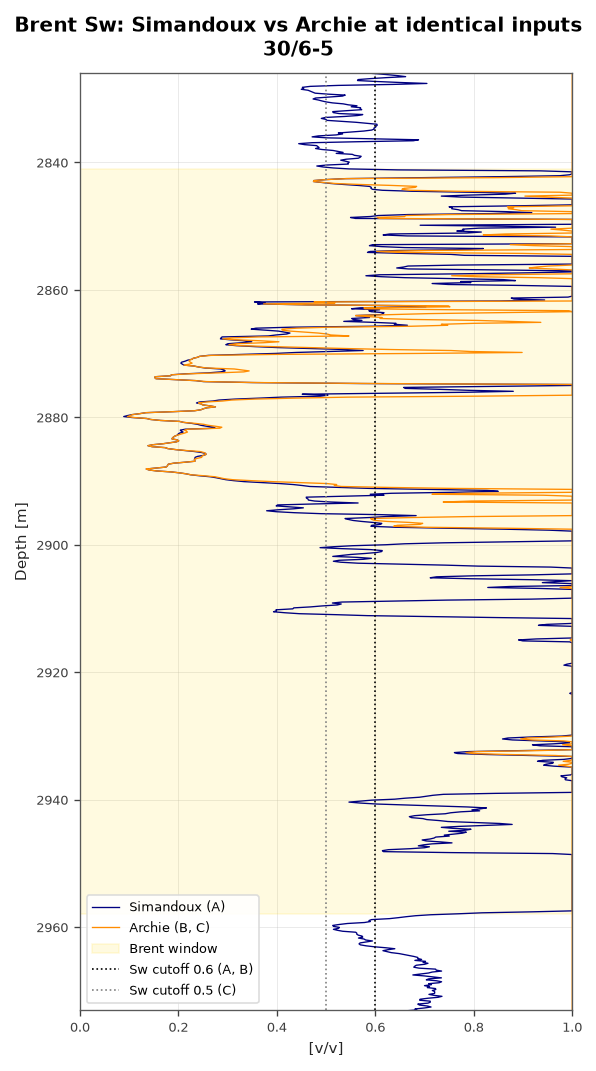

In [14]:
from petrophys.visualization import LogPlot

# LogPlot draws curves from one well, so copy both Sw arrays onto run A's well
# as distinctly named curves (all runs share the same depth grid).
wA = rA.well
wA.add_curve("SW_SIMANDOUX", rA.well.get("SW").data, unit="v/v",
             description="Sw from run A (Simandoux)")
wA.add_curve("SW_ARCHIE", rB.well.get("SW").data, unit="v/v",
             description="Sw from runs B and C (Archie)")

lp = LogPlot(wA, figsize=(5, 9))
lp.create_figure(n_tracks=1)
lp.add_curve(0, "SW_SIMANDOUX", color="navy", linewidth=0.8,
             label="Simandoux (A)", xlim=(0, 1))
lp.add_curve(0, "SW_ARCHIE", color="darkorange", linewidth=0.8,
             label="Archie (B, C)")
lp.set_depth_range(top=BRENT_TOP - 15, bottom=BRENT_BASE + 15)

ax = lp.axes[0]
ax.axhspan(BRENT_TOP, BRENT_BASE, color="gold", alpha=0.12, label="Brent window")
ax.axvline(0.6, color="black", ls=":", lw=1, label="Sw cutoff 0.6 (A, B)")
ax.axvline(0.5, color="grey", ls=":", lw=1, label="Sw cutoff 0.5 (C)")
ax.legend(loc="lower left", fontsize=8)

lp.add_title("Brent Sw: Simandoux vs Archie at identical inputs")
lp.show()

## 7. Zoned parameters and a per-formation summary

Real wells rarely use one set of parameters top to bottom. Some LAS files carry
*zoned* parameters in the header (`RW_Z1`, `RW_Z2`, ...).
`run_dynamic_workflow_with_zones` reads them, runs the workflow per zone and
merges the results. Like `pp.run_dynamic_workflow`, it is a lower-level helper
that adds the calculated curves to the well you pass in; we use it because it
is the entry point for zoned header parameters.

30/6-5's LAS carries **no** zoned parameters, so the helper finds zero zones.
It does read the **global** header block (RW, RMF, BHT, and the filtrate
chloride CLFL as `rmf_chlorides_mg_l`), but header values only fill settings you
left unset: an explicitly configured value always wins, and
the run's warnings say so. Here the header and the config agree (Rw 0.070 ohm.m
at 230 degF), so the warnings below only record the precedence; it matters when
a header value is wrong or has no temperature basis.

In [15]:
wz = load_well()
zres = run_dynamic_workflow_with_zones(wz, DynamicWorkflowConfig(sw_cutoff=0.6, **BASE))
print("Zoned helper ran. Base status:", zres.base_result.status)
print("Explicit LAS-defined zones found:", len(zres.zones))
print("Global header parameters found:", sorted(zres.global_overrides) or "none")
print("Warnings (note the header-vs-config precedence):")
for note in (zres.warnings or ["none"]):
    print("  -", note)

Zoned helper ran. Base status: interpreted
Explicit LAS-defined zones found: 0
Global header parameters found: ['rmf_chlorides_mg_l']
Warnings (note the header-vs-config precedence):
  - none


### Summarising the interpretation per formation

The helper's `base_result` is an ordinary `DynamicWorkflowResult`, so its
`formation_summary` method rolls the curves up per formation. The bundled tops
for 30/6-5 mix groups and their member formations, so we ask for one level with
`rank="formation"`; the rows then do not overlap. They also do not cover the
whole well: depth that has a group top but no member-formation top (most of the
Nordland and Hordaland groups, and the Shetland and Cromer Knoll groups) falls
in no formation-rank row, so the cell also prints the net pay that the rows
leave out. (Lesson 11 covers formation analysis in depth.)

In [16]:
fsum = zres.base_result.formation_summary(pp.sample("formations_30_6-5"), rank="formation")
cols = ["Formation", "Top", "Bottom", "Gross (m)", "Net Pay (m)", "NTG",
        "Avg PHIE", "Avg Sw", "Avg VCL"]
print(fsum[cols].round(3).to_string(index=False))

above = fsum["Top"] < BRENT_TOP
print()
print("Net pay flagged from the Brent top down : %.1f m" % fsum.loc[~above, "Net Pay (m)"].sum())
print("Net pay flagged in formations above it  : %.1f m" % fsum.loc[above, "Net Pay (m)"].sum())
whole_well = zres.base_result.summary()["net_thickness"]["net_pay"]
print("Net pay flagged in the whole well       : %.1f m" % whole_well)
print("  ... in no formation-rank row          : %.1f m" % (whole_well - fsum["Net Pay (m)"].sum()))

    Formation    Top  Bottom  Gross (m)  Net Pay (m)   NTG  Avg PHIE  Avg Sw  Avg VCL
   Utsira Fm.  726.0   879.0    153.010        0.000 0.000       NaN     NaN      NaN
   Balder Fm. 1908.0  2023.0    115.062        0.000 0.000       NaN     NaN      NaN
     Sele Fm. 2023.0  2123.0     99.974        0.000 0.000       NaN     NaN      NaN
    Lista Fm. 2123.0  2203.0     80.010        0.000 0.000       NaN     NaN      NaN
  Draupne Fm. 2452.0  2593.0    140.970        0.000 0.000       NaN     NaN      NaN
  Heather Fm. 2593.0  2841.0    247.955        0.000 0.000       NaN     NaN      NaN
     Ness Fm. 2841.0  2865.0     24.079        1.829 0.076     0.209   0.528    0.027
    Etive Fm. 2865.0  2958.0     92.964       22.708 0.244     0.211   0.273    0.056
    Drake Fm. 2958.0  3071.0    113.081        0.000 0.000       NaN     NaN      NaN
     Cook Fm. 3071.0  3123.0     51.968        0.000 0.000       NaN     NaN      NaN
 Amundsen Fm. 3123.0  3223.0     99.975        0.000 0

Read each row with its geology before adding anything up:

- **Ness and Etive** (the Brent Group) are the reservoir; compare their net pay
  with the Brent window totals in section 6.
- The formation rows **above the Brent** show no net pay here, but that does
  not make the overburden clean. The whole-well total printed above is larger
  than the sum of the rows, because flags in depth that no formation-rank row
  covers - mostly the Hordaland Group mudstones between the Utsira and the
  Rogaland tops (879-1908 m) - are left out. These are the same shallow flags
  section 6 counted above 1908 m. `rank="group"` shows them. Poorly compacted
  or silty rock there can pass the cutoffs; it lies outside the reservoir
  interval studied here and needs independent evidence (pressures, shows,
  tests) before anyone counts it.
- The thin flag in the deeper Statfjord Formation is a review candidate, not a
  completion recommendation.

So a per-formation table is complete only if the tops cover the whole well at
the chosen rank; check the uncovered net pay before quoting a total. A cutoff
flag alone is never a pay call.

## Pitfalls and parameter choices

- `pp.interpret` copies the well. `pp.run_dynamic_workflow` and the zoned
  helper add curves to the well you pass in.
- Workflow normalization is on by default: with `standardize_input` left unset,
  curve aliases and units are standardized and implausible values screened, with
  a warning; pass `standardize_input=False` to interpret the curves as read.
- Header values still need a unit and temperature basis. Always pass Rw with
  `rw_meas_temp_f`; without it the workflow takes Rw at the median formation
  temperature. Our Rw (0.070 ohm.m at 230 degF, as in the header) is an
  explicit study value, checked in lesson 09.
- Net-pay cutoffs do not know where the reservoir is. Total pay over a
  reservoir window chosen from geology (`result.summary(top=..., bottom=...)`);
  whole-well totals include overburden flags.
- The net-pay flags leave out `BAD_HOLE`, evaporite and coal samples, and halite
  recognised from its logs; the `net_pay` decisions say how much thickness each
  removed. Unset cutoffs follow each sample's lithology family; pin them when a
  report must be reproducible.
- Check status, skipped steps, errors and warnings, not just the final plot.
- A source-selection policy does not establish that a vendor codebook or
  unknown lithology label is scientifically correct.
- Zoned overrides require the corresponding LAS parameters; missing zonation is
  not reconstructed from formation names.

## Recap

- `pp.interpret` auto-detects inputs, selects a method per module, and runs the
  full QC -> Vcl -> porosity -> lithology -> Rw -> Sw -> permeability -> rock
  quality -> net pay pipeline on a copy of the well
  (`pp.run_dynamic_workflow` is the in-place, lower-level form).
- `DynamicWorkflowResult` is a **glass box**: `status`, `steps_executed`,
  `steps_skipped` with reasons in `specific_steps_skipped`, per-step `method` /
  `input_curves` / `output_curves` / `parameters` / `decisions`, and
  `to_dataframe()`.
- Overriding `sw_model` and `sw_cutoff` moves net pay in a documented,
  reproducible way; `result.summary(top=..., bottom=...)` measures it over the
  reservoir window, where the comparison means something.
- `result.formation_summary(rank="formation")` gives the per-formation view;
  flags outside the reservoir need geological review, not summation.

## Try it yourself

> **Exercise 1.** Re-run the workflow with `apply_hc_correction=True` and
> `hc_type="oil"`. Confirm `hc_correction` now appears in `steps_executed`,
> then compare the `NPHI` and `NPHI_HC` curves directly over the reservoir
> section. (The corrected curves are written for inspection; downstream steps
> do not consume `NPHI_HC`/`RHOB_HC`, so PHIE is unchanged.)
>
> **Exercise 2.** Set `phie_cutoff=0.12` (tighter porosity cutoff) and compare
> net pay per formation (`formation_summary(..., rank="formation")`) against
> the base run. Which formations lose the most?
>
> **Exercise 3.** Export the full audit trail with
> `result.to_json("trace.json")` and open it - every routing decision is
> serialised.

## What's next

Continue with **11 - Formation & Interval Analysis**, which builds a
formation/zone hierarchy from the tops and per-interval lithology CSVs and
produces formation-level NTG / net-pay reporting with depth-track shading.